# NB_SUMMARY — Bảng so sánh tổng hợp (một chuẩn, một cách gộp)

Gom mọi model về **cùng thước đo per-question atomic** VÀ **cùng cách gộp** (tính
metric từng câu trong không gian nhãn riêng của câu, rồi trung bình đều — KHÔNG gộp
chung không gian nhãn khác loại):
- **Prior** (sàn) — đoán đa số theo từng câu.
- **ViT-L/14 + MLP** (và ViT-B/32) — đầu riêng cho từng câu (NB1, mốc tham chiếu).
- **PhoBERT + ViT-L dùng-chung** — MỘT model cho cả 10 câu (NB2, mô hình chính hiện tại).

> Lưu ý gộp metric: bản trước tính `single F1-macro` bằng cách **gộp chung** nhãn đếm
> của Q6 (0..5+) với nhãn yes/no → 1 câu chi phối macro-F1, kéo điểm xuống giả tạo
> (0.58). Bản này tính **từng câu rồi trung bình** (mỗi câu 1 phần bằng nhau) → phản
> ánh đúng (~0.70). Nhóm *what* vốn đã tính per-question nên không đổi.

In [1]:
import os, sys
import numpy as np, pandas as pd
from sklearn.metrics import f1_score
if os.path.basename(os.getcwd())!="experiments" and os.path.isdir("F:/VQA/experiments"):
    os.chdir("F:/VQA/experiments")
import unified as U
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd())=="experiments" else "F:/VQA","imbalance_study"))
import run_imbalance as RR
vit=U.load_vit("_vitl"); pho=U.load_phobert()
feat_vitl=RR.load_features("_vitl"); feat_b32=RR.load_features("")
tr=pd.read_csv(os.path.join(U.QA,"train.csv")); tr["qid"]=tr["qid"].astype(str)
te=pd.read_csv(os.path.join(U.QA,"test.csv")); te["qid"]=te["qid"].astype(str)
full=pd.concat([tr,pd.read_csv(os.path.join(U.QA,"val.csv")).assign(qid=lambda d:d["qid"].astype(str)),te],ignore_index=True)
vocab,idx,cand=U.build_global_vocab(full)

## 1. Prior atomic (sàn) — per-question rồi trung bình

In [2]:
Xtr,Ytr,qtr,_=U.build_rows(tr,vit,pho,idx,"full")
Xte,Yte,qte,_=U.build_rows(te,vit,pho,idx,"full")
A=len(vocab); prior_pred=np.zeros((len(Xte),A),dtype=int)
for q in U.QID_ORDER:
    mtr=qtr==q; mte=qte==q
    if mte.sum()==0: continue
    cd=cand[q]; freq=Ytr[mtr][:,cd].mean(0)
    if q in U.WHAT_QIDS:
        take=[c for c,f in zip(cd,freq) if f>=0.5]
        if not take: take=[cd[int(np.argmax(freq))]]
        prior_pred[np.ix_(np.where(mte)[0],take)]=1
    else:
        prior_pred[np.where(mte)[0],cd[int(np.argmax(freq))]]=1
pw,ps,_=U.score_tables(prior_pred,Yte,qte,cand,vocab)
print("Prior  what F1-macro=%.3f | single F1-macro=%.3f EM=%.3f"%(pw["F1_macro"],ps["F1ma"],ps["EM"]))

Prior  what F1-macro=0.148 | single F1-macro=0.384 EM=0.717


## 2. ViT+MLP đầu-riêng — tính lại single bằng per-question-average (khớp cách gộp)

Nhóm *what* lấy từ NB1 (vốn đã per-question). Nhóm *single* tính lại tại đây: F1-macro
mỗi câu (trong không gian nhãn riêng) rồi trung bình — để so công bằng với model dùng-chung.

In [3]:
def vitmlp_single_f1(feat):
    f1s=[]
    for q in RR.SINGLE_QIDS:
        Xa,ya=RR.qid_rows(tr,feat,q); Xb,yb=RR.qid_rows(te,feat,q)
        if q in RR.DERIVED_BIN: ya,yb=RR.to_binary(ya),RR.to_binary(yb)
        gt,pr=RR.run_qid_single("baseline",Xa,ya,Xb,yb)
        f1s.append(f1_score(gt,pr,average="macro",zero_division=0))
    return float(np.mean(f1s))
nb1w=pd.read_csv("results/nb1_what_vitl.csv")
vitl_w_base=float(nb1w[nb1w["method"]=="baseline"]["F1_macro"]); vitl_w_best=float(nb1w["F1_macro"].max())
abl=pd.read_csv("results/nb1_encoder_ablation.csv"); b32_w=float(abl[abl["nhóm"]=="what (F1-macro)"]["ViT-B/32"])
vitl_s_base=vitmlp_single_f1(feat_vitl); b32_s=vitmlp_single_f1(feat_b32)
print("ViT-L single (per-q avg)=%.4f | ViT-B/32 single=%.4f"%(vitl_s_base,b32_s))

ViT-L single (per-q avg)=0.7369 | ViT-B/32 single=0.7025


## 3. Model dùng-chung (NB2) — số đã tính đúng cách gộp

In [4]:
nb2=pd.read_csv("results/nb2_shared_methods.csv")
nb2_w_base=float(nb2.iloc[0]["what_F1macro"]); nb2_w_best=float(nb2["what_F1macro"].max())
nb2_s_base=float(nb2.iloc[0]["single_F1macro"]); nb2_s_best=float(nb2["single_F1macro"].max())
best_single_method=nb2.loc[nb2["single_F1macro"].idxmax(),"mô_hình"]
print("Shared what base=%.3f best=%.3f | single base=%.3f best=%.3f (%s)"%(nb2_w_base,nb2_w_best,nb2_s_base,nb2_s_best,best_single_method))

Shared what base=0.676 best=0.678 | single base=0.717 best=0.735 (+ Threshold-moving)


## 4. BẢNG TỔNG HỢP — F1-macro (một chuẩn, một cách gộp)

In [5]:
master=pd.DataFrame([
 {"Mô hình":"Prior (majority) — sàn","what_F1macro":round(pw["F1_macro"],4),"single_F1macro":round(ps["F1ma"],4),"ghi chú":"không dùng ảnh"},
 {"Mô hình":"ViT-B/32 + MLP (baseline)","what_F1macro":round(b32_w,4),"single_F1macro":round(b32_s,4),"ghi chú":"đầu riêng/câu (tham chiếu)"},
 {"Mô hình":"ViT-L/14 + MLP (baseline)","what_F1macro":round(vitl_w_base,4),"single_F1macro":round(vitl_s_base,4),"ghi chú":"đầu riêng/câu (tham chiếu)"},
 {"Mô hình":"ViT-L/14 + MLP (tốt nhất)","what_F1macro":round(vitl_w_best,4),"single_F1macro":round(vitl_s_base,4),"ghi chú":"+ cân bằng (what)"},
 {"Mô hình":"PhoBERT+ViT-L dùng-chung (baseline)","what_F1macro":round(nb2_w_base,4),"single_F1macro":round(nb2_s_base,4),"ghi chú":"★ MÔ HÌNH CHÍNH: 1 model/10 câu"},
 {"Mô hình":"PhoBERT+ViT-L dùng-chung (tốt nhất)","what_F1macro":round(nb2_w_best,4),"single_F1macro":round(nb2_s_best,4),"ghi chú":"★ + cân bằng"},
])
master.to_csv("results/master_comparison.csv",index=False)
master

,Mô hình,what_F1macro,single_F1macro,ghi chú
0,Prior (majority) — sàn,0.1475,0.3844,không dùng ảnh
1,ViT-B/32 + MLP (baseline),0.6645,0.7025,đầu riêng/câu (tham chiếu)
2,ViT-L/14 + MLP (baseline),0.6952,0.7369,đầu riêng/câu (tham chiếu)
3,ViT-L/14 + MLP (tốt nhất),0.6970,0.7369,+ cân bằng (what)
4,PhoBERT+ViT-L dùng-chung (baseline),0.6760,0.7172,★ MÔ HÌNH CHÍNH: 1 model/10 câu
5,PhoBERT+ViT-L dùng-chung (tốt nhất),0.6780,0.7353,★ + cân bằng


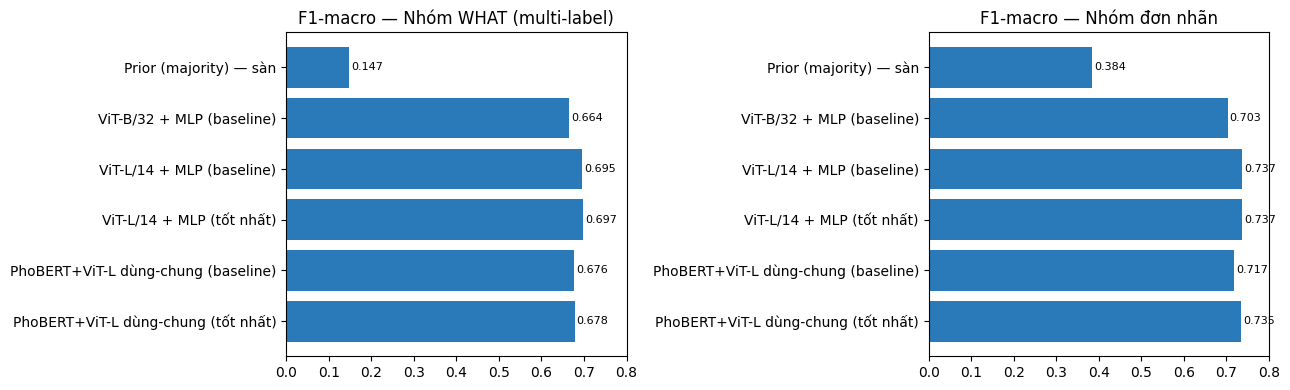

In [6]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(13,4))
for a,col,tt in zip(ax,["what_F1macro","single_F1macro"],["Nhóm WHAT (multi-label)","Nhóm đơn nhãn"]):
    a.barh(master["Mô hình"],master[col],color="#2a7ab9"); a.set_title(f"F1-macro — {tt}")
    a.invert_yaxis(); a.set_xlim(0,0.8)
    for i,v in enumerate(master[col]): a.text(v+0.005,i,f"{v:.3f}",va="center",fontsize=8)
plt.tight_layout(); plt.savefig("results/master_comparison.png",dpi=110); plt.show()

## 5. Ghi chú quan trọng cho báo cáo

- **Q6 (đếm xe máy)**: F1-macro phẳng (~0.47) đánh giá oan vì đếm là bài toán *thứ tự*.
  Model đúng **trong ngưỡng ±1 mức đếm tới ~0.91**. Báo cáo Q6 nên dùng metric ±1 này.
- **AUC-ROC ~0.89–0.91** (NB3) cho thấy model phân biệt lớp tốt; F1-macro thấp hơn là
  do ngưỡng + mất cân bằng, không phải model "không học được".
- Mọi model **vượt sàn Prior** rõ rệt → đặc trưng ảnh + câu hỏi thực sự có ích.
- Số liệu **cùng một chuẩn, cùng một cách gộp** → xếp chung bảng so sánh trực tiếp.

File: `results/master_comparison.csv`, `results/master_comparison.png`.